In [1]:
!pip install qiskit qiskit-aer matplotlib

Defaulting to user installation because normal site-packages is not writeable

DEPRECATION: Loading egg at c:\programdata\anaconda3\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330


In [17]:
# EASY: Simon's Oracle for secret string 110
from qiskit import QuantumCircuit

s = "110"
n = len(s)

def f(x):
    return min(x, x ^ int(s, 2))

print("Truth Table")
for x in range(2**n):
    print(format(x, "03b"), "->", format(f(x), "03b"))

print("\nOracle is correct because f(x) = f(x XOR s)")

Truth Table
000 -> 000
001 -> 001
010 -> 010
011 -> 011
100 -> 010
101 -> 011
110 -> 000
111 -> 001

Oracle is correct because f(x) = f(x XOR s)


In [19]:
# MEDIUM: Simon's Algorithm for 3-bit secret 110
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.circuit.library import UnitaryGate
import numpy as np

secret = "110"
n = len(secret)
s = int(secret, 2)

def f(x):
    return min(x, x ^ s)
size = 2 ** (2 * n)
U = np.zeros((size, size))

for x in range(2**n):
    for y in range(2**n):
        inp = x | (y << n)
        out = x | ((y ^ f(x)) << n)
        U[out, inp] = 1

oracle = UnitaryGate(U, label="Oracle")

qc = QuantumCircuit(2*n, n)

for i in range(n):
    qc.h(i)

qc.append(oracle, range(2*n))
for i in range(n):
    qc.h(i)
for i in range(n):
    qc.measure(i, i)

print("SIMON'S ALGORITHM")
print(qc.draw())

simulator = AerSimulator()
result = simulator.run(
    transpile(qc, simulator),
    shots=1024
).result()

counts = result.get_counts()

print("\nMeasurement Results:")
print(counts)
print("\nMeasurement Equations:")

for bitstring in counts:
    if bitstring != "000":
        print(bitstring, "· s = 0")

SIMON'S ALGORITHM
     ┌───┐┌─────────┐┌───┐┌─┐      
q_0: ┤ H ├┤0        ├┤ H ├┤M├──────
     ├───┤│         │├───┤└╥┘┌─┐   
q_1: ┤ H ├┤1        ├┤ H ├─╫─┤M├───
     ├───┤│         │├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├┤2        ├┤ H ├─╫──╫─┤M├
     └───┘│  Oracle │└───┘ ║  ║ └╥┘
q_3: ─────┤3        ├──────╫──╫──╫─
          │         │      ║  ║  ║ 
q_4: ─────┤4        ├──────╫──╫──╫─
          │         │      ║  ║  ║ 
q_5: ─────┤5        ├──────╫──╫──╫─
          └─────────┘      ║  ║  ║ 
c: 3/══════════════════════╩══╩══╩═
                           0  1  2 

Measurement Results:
{'000': 265, '111': 249, '110': 260, '001': 250}

Measurement Equations:
111 · s = 0
110 · s = 0
001 · s = 0


In [24]:
# HARD: 4-bit Simon's Algorithm + GF(2) Linear Equations
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.circuit.library import UnitaryGate
import numpy as np

secret = "1011"
n = len(secret)
s = int(secret, 2)

def simon_function(x, s):
    return min(x, x ^ s)
def create_oracle(secret):
    n = len(secret)
    s = int(secret, 2)
    size = 2 ** (2 * n)
    matrix = np.zeros((size, size))
    for x in range(2 ** n):
        fx = simon_function(x, s)
        for y in range(2 ** n):
            input_state = x | (y << n)
            output_state = x | ((y ^ fx) << n)
            matrix[output_state, input_state] = 1
    return UnitaryGate(matrix,label="Simon Oracle")
def rank_gf2(rows, n):
    matrix = [row[:] for row in rows]
    rank = 0
    for col in range(n):
        pivot = None
        for row in range(rank, len(matrix)):
            if matrix[row][col] == 1:
                pivot = row
                break
        if pivot is None:
            continue
        matrix[rank], matrix[pivot] = (matrix[pivot],matrix[rank])
        for row in range(len(matrix)):
            if row != rank and matrix[row][col] == 1:
                for j in range(col, n):
                    matrix[row][j] ^= matrix[rank][j]
        rank += 1
    return rank
def nullspace_gf2(rows, n):
    matrix = [row[:] for row in rows]
    rank = 0
    pivots = []
    for col in range(n): 
        pivot = None
        for row in range(rank, len(matrix)):
            if matrix[row][col] == 1:
                pivot = row
                break
        if pivot is None:
            continue
        matrix[rank], matrix[pivot] = (matrix[pivot],matrix[rank])
        for row in range(len(matrix)):
            if row != rank and matrix[row][col] == 1:
                for j in range(n):
                    matrix[row][j] ^= matrix[rank][j]
        pivots.append(col)
        rank += 1
    free_variables = [
        i for i in range(n)
        if i not in pivots
    ]
    basis = []
    for free in free_variables:
        vector = [0] * n
        vector[free] = 1
        for i, pivot in enumerate(pivots):
            vector[pivot] = matrix[i][free]
        basis.append(vector)
    return basis
qc = QuantumCircuit(2 * n,n)
for i in range(n):
    qc.h(i)
oracle = create_oracle(secret)
qc.append(oracle,range(2 * n))
for i in range(n):
    qc.h(i)
for i in range(n):
    qc.measure(i, i)
print("4-BIT SIMON CIRCUIT")
print("-------------------")
print(qc.draw())
simulator = AerSimulator()

compiled = transpile(qc,simulator)
result = simulator.run(compiled,shots=4096).result()
counts = result.get_counts()
print("\nMEASUREMENT RESULTS")
print("-------------------")
print(counts)
equations = []
for bitstring in counts:
    if bitstring == "0000":
        continue
    equation = [
        int(bit)
        for bit in bitstring
    ]
    old_rank = rank_gf2(equations,n)
    new_rank = rank_gf2(equations + [equation],n)
    if new_rank > old_rank:
        equations.append(equation)
    if len(equations) >= n - 1:
        break
print("\nINDEPENDENT EQUATIONS")
print("---------------------")
for equation in equations:
    print("".join(map(str, equation)),"· s = 0")
solutions = nullspace_gf2(equations,n)

print("\nSOLUTIONS")
print("---------")
for solution in solutions:
    print(solution)
if len(solutions) == 1:
    recovered = "".join(map(str, solutions[0]))
    print("\nRECOVERED SECRET:", recovered)
    print("ACTUAL SECRET   :", secret)
else:
    print("\nMore measurements are required ""to determine the secret.")

4-BIT SIMON CIRCUIT
-------------------
     ┌───┐┌───────────────┐┌───┐┌─┐         
q_0: ┤ H ├┤0              ├┤ H ├┤M├─────────
     ├───┤│               │├───┤└╥┘┌─┐      
q_1: ┤ H ├┤1              ├┤ H ├─╫─┤M├──────
     ├───┤│               │├───┤ ║ └╥┘┌─┐   
q_2: ┤ H ├┤2              ├┤ H ├─╫──╫─┤M├───
     ├───┤│               │├───┤ ║  ║ └╥┘┌─┐
q_3: ┤ H ├┤3              ├┤ H ├─╫──╫──╫─┤M├
     └───┘│  Simon Oracle │└───┘ ║  ║  ║ └╥┘
q_4: ─────┤4              ├──────╫──╫──╫──╫─
          │               │      ║  ║  ║  ║ 
q_5: ─────┤5              ├──────╫──╫──╫──╫─
          │               │      ║  ║  ║  ║ 
q_6: ─────┤6              ├──────╫──╫──╫──╫─
          │               │      ║  ║  ║  ║ 
q_7: ─────┤7              ├──────╫──╫──╫──╫─
          └───────────────┘      ║  ║  ║  ║ 
c: 4/════════════════════════════╩══╩══╩══╩═
                                 0  1  2  3 

MEASUREMENT RESULTS
-------------------
{'1010': 526, '1001': 484, '0111': 501, '1101': 499, '0100': 554

n	Quantum Queries	Classical Queries	Speedup
------------------------------------------------------------
2 	 2 		 4 		 2.0
3 	 3 		 8 		 2.67
4 	 4 		 16 		 4.0
5 	 5 		 32 		 6.4
6 	 6 		 64 		 10.67
7 	 7 		 128 		 18.29
8 	 8 		 256 		 32.0
9 	 9 		 512 		 56.89
10 	 10 		 1024 		 102.4


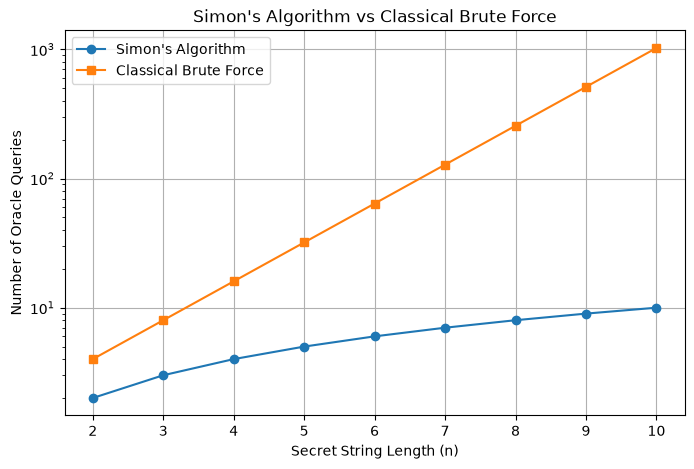

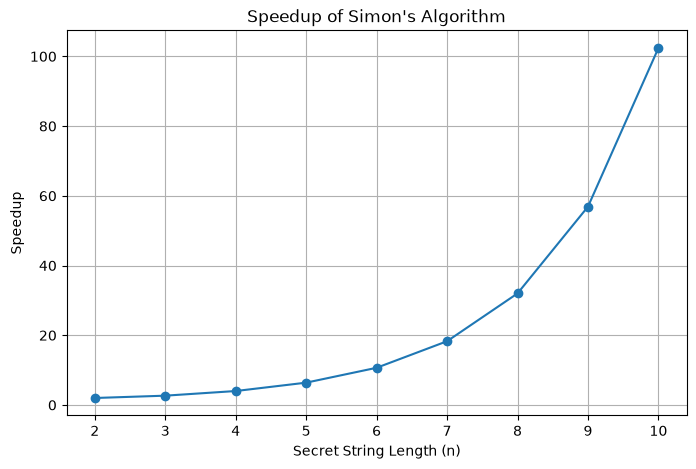

In [25]:
# REAL-WORLD: Simon's Algorithm vs Classical Brute Force
import matplotlib.pyplot as plt
n_values = list(range(2, 11))
quantum_queries = []
classical_queries = []
for n in n_values:
    quantum_queries.append(n)
    classical_queries.append(2 ** n)
speedup = []
for i in range(len(n_values)):
    speedup.append(classical_queries[i]/ quantum_queries[i])
print("n\tQuantum Queries\tClassical Queries\tSpeedup")
print("-" * 60)

for i in range(len(n_values)):
    print(n_values[i],"\t",quantum_queries[i],"\t\t",classical_queries[i],"\t\t",round(speedup[i], 2))

plt.figure(figsize=(8, 5))
plt.plot(n_values,quantum_queries,marker="o",label="Simon's Algorithm")
plt.plot(n_values,classical_queries,marker="s",label="Classical Brute Force")
plt.xlabel("Secret String Length (n)")
plt.ylabel("Number of Oracle Queries")
plt.title("Simon's Algorithm vs Classical Brute Force")
plt.yscale("log")
plt.grid(True)
plt.legend()
plt.show()
plt.figure(figsize=(8, 5))
plt.plot(n_values,speedup,marker="o")
plt.xlabel("Secret String Length (n)")
plt.ylabel("Speedup")
plt.title("Speedup of Simon's Algorithm")
plt.grid(True)
plt.show()

In [9]:
# CHALLENGE: Generalized Simon's Algorithm
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.circuit.library import UnitaryGate
import numpy as np
def simon_function(x, s):
    return min(x, x ^ s)
def create_oracle(secret):
    n = len(secret)
    s = int(secret, 2)
    size = 2 ** (2 * n)
    matrix = np.zeros((size, size))
    for x in range(2 ** n):
        fx = simon_function(x, s)
        for y in range(2 ** n):
            input_state = x | (y << n)
            output_state = x | ((y ^ fx) << n)
            matrix[output_state, input_state] = 1
    return UnitaryGate(matrix,label="Simon Oracle")
def rank_gf2(rows, n):
    matrix = [row[:] for row in rows]
    rank = 0
    for col in range(n):
        pivot = None
        for row in range(rank, len(matrix)):
            if matrix[row][col] == 1:
                pivot = row
                break
        if pivot is None:
            continue
        matrix[rank], matrix[pivot] = (matrix[pivot],matrix[rank])
        for row in range(len(matrix)):
            if row != rank and matrix[row][col] == 1:
                for j in range(col, n):
                    matrix[row][j] ^= matrix[rank][j]
        rank += 1
    return rank
def nullspace_gf2(rows, n):
    matrix = [row[:] for row in rows]
    rank = 0
    pivots = []
    for col in range(n):
        pivot = None
        for row in range(rank, len(matrix)):
            if matrix[row][col] == 1:
                pivot = row
                break
        if pivot is None:
            continue
        matrix[rank], matrix[pivot] = (matrix[pivot],matrix[rank])
        for row in range(len(matrix)):
            if row != rank and matrix[row][col] == 1:
                for j in range(n):
                    matrix[row][j] ^= matrix[rank][j]
        pivots.append(col)
        rank += 1
    free_variables = [i for i in range(n)if i not in pivots]
    basis = []
    for free in free_variables:
        vector = [0] * n
        vector[free] = 1
        for i, pivot in enumerate(pivots):
            vector[pivot] = matrix[i][free]
        basis.append(vector)
    return basis
def generalized_simon(secret):
    n = len(secret)
    print("=" * 50)
    print("GENERALIZED SIMON'S ALGORITHM")
    print("=" * 50)
    print("Secret string:", secret)
    print("Number of bits:", n)
    qc = QuantumCircuit(2 * n,n)
    for i in range(n):
        qc.h(i)
    oracle = create_oracle(secret)
    qc.append(oracle,range(2 * n))
    for i in range(n):
        qc.h(i)
    for i in range(n):
        qc.measure(i, i)
    simulator = AerSimulator()
    compiled = transpile(qc,simulator)
    result = simulator.run(compiled,shots=8192).result()
    counts = result.get_counts()
    print("\nMeasurement Results:")
    print(counts)
    equations = []
    for bitstring in counts:
        equation = [
            int(bit)
            for bit in bitstring
        ]
        old_rank = rank_gf2(equations,n)
        new_rank = rank_gf2(equations + [equation],n)
        if new_rank > old_rank:
            equations.append(equation)
        if len(equations) >= n - 1:
            break
    print("\nIndependent Equations:")
    for equation in equations:
        print("".join(map(str, equation)),"· s = 0")
    solutions = nullspace_gf2(equations,n)
    if secret == "0" * n:
        recovered = "0" * n
    elif len(solutions) == 1:
        recovered = "".join(map(str, solutions[0]))
    else:
        recovered = "Unable to determine"
    print("\nRecovered Secret:", recovered)
    print("Actual Secret   :", secret)
    return recovered
print("\nTEST 1")
generalized_simon("110")
print("\nTEST 2")
generalized_simon("1011")
print("\nTEST 3")
generalized_simon("10101")
print("\nTEST 4 - ALL ZERO CASE")
generalized_simon("000")


TEST 1
GENERALIZED SIMON'S ALGORITHM
Secret string: 110
Number of bits: 3

Measurement Results:
{'110': 2024, '111': 2033, '001': 2125, '000': 2010}

Independent Equations:
110 · s = 0
111 · s = 0

Recovered Secret: 110
Actual Secret   : 110

TEST 2
GENERALIZED SIMON'S ALGORITHM
Secret string: 1011
Number of bits: 4

Measurement Results:
{'1001': 989, '1010': 1015, '1101': 1085, '0100': 984, '0000': 1029, '0111': 1074, '0011': 1042, '1110': 974}

Independent Equations:
1001 · s = 0
1010 · s = 0
1101 · s = 0

Recovered Secret: 1011
Actual Secret   : 1011

TEST 3
GENERALIZED SIMON'S ALGORITHM
Secret string: 10101
Number of bits: 5

Measurement Results:
{'11100': 507, '10011': 496, '00010': 542, '10100': 504, '00101': 521, '01111': 470, '10001': 521, '11110': 563, '11011': 521, '01000': 530, '01010': 496, '00000': 499, '01101': 498, '00111': 535, '10110': 496, '11001': 493}

Independent Equations:
11100 · s = 0
10011 · s = 0
00010 · s = 0
10100 · s = 0

Recovered Secret: 10101
Actual Sec

'000'